In [1]:
# import useful libraries
import numpy as np
import matplotlib.pyplot as plt

import os
import sys

# add parent directory to sys.path to import STL package modules
PARENT_DIR = os.path.dirname(os.path.abspath(os.getcwd() + "../../../"))
sys.path.append(PARENT_DIR)
print("Parent directory added to sys.path:", ".../" + PARENT_DIR.split("/")[-1])

# test data directory
DATA_TEST_PATH = PARENT_DIR + "/data" + "/test"
print("Dataset dirctory used:", ".../" + PARENT_DIR.split("/")[-1] + DATA_TEST_PATH.split(PARENT_DIR.split("/")[-1])[-1])

from STL_main.STL_2D_Kernel_Torch import STL_2D_Kernel_Torch
DataClass = STL_2D_Kernel_Torch
from STL_main.Synthesis import optimize_from_maps
from STL_main.torch_backend import _DEFAULT_DEVICE

print("Working on device:", _DEFAULT_DEVICE)


import torch
from pyinstrument import Profiler

Parent directory added to sys.path: .../STL-Dev
Dataset dirctory used: .../STL-Dev/data/test


/Users/richard/Desktop/STL/STL-Dev/STL_main/__init__.py:9: UserWarning: In development mode: Please run 'pip install -e .' in the root directory of the STL repository to properly install the package, its dependencies and enable proper version tracking.
  warnings.warn(


Working on device: mps


In [2]:
# command to auto-reload modules when they are edited (easier for testing and debugging)
%load_ext autoreload
%autoreload 2

In [3]:
from STL_main.Tensor_Product_Kernel_Torch import STL_TensorProd_Kernel_Torch
from STL_main.STL_2D_Kernel_Torch import STL_2D_Kernel_Torch
from STL_main.STL_1D_Kernel_Torch import STL_1D_Kernel_Torch

In [41]:
seed = 42
torch.manual_seed(seed)

if False:
    test_array = torch.rand((64, 64, 128, 32), device="cpu") # cpu: 15min (40min slow dg) | DATARMOR GPU1 12s slow dg (9s fast dg)

    a = STL_TensorProd_Kernel_Torch(
        array=test_array, 
        data_structure=[STL_2D_Kernel_Torch, STL_1D_Kernel_Torch, STL_1D_Kernel_Torch], 
        pbc=[False, False, False], 
    )
elif False:
    test_array = torch.rand((32, 128, 64, 64), device="cpu") # cpu: 4min7s (10min slow dg) | DATARMOR GPU1 7.4s slow dg (7s fast dg)

    a = STL_TensorProd_Kernel_Torch(
        array=test_array, 
        data_structure=[STL_1D_Kernel_Torch, STL_1D_Kernel_Torch, STL_2D_Kernel_Torch], 
        pbc=[False, False, False], 
    )
elif False:
    test_array = torch.rand((128, 32, 64, 64), device="cpu") # cpu: 4min6s (? slow dg) | DATARMOR GPU1 7.4s slow dg

    a = STL_TensorProd_Kernel_Torch(
        array=test_array, 
        data_structure=[STL_1D_Kernel_Torch, STL_1D_Kernel_Torch, STL_2D_Kernel_Torch], 
        pbc=[False, False, False], 
    )
elif False:
    test_array = torch.rand((4, 1, 32, 128, 64, 64), device="cpu") # DATARMOR GPU1 16s slow dg

    a = STL_TensorProd_Kernel_Torch(
        array=test_array, 
        data_structure=[STL_1D_Kernel_Torch, STL_1D_Kernel_Torch, STL_2D_Kernel_Torch], 
        pbc=[False, False, False], 
    )
elif False:
    test_array = torch.rand((32, 32, 16, 16), device="cpu")

    a = STL_TensorProd_Kernel_Torch(
        array=test_array, 
        data_structure=[STL_2D_Kernel_Torch, STL_1D_Kernel_Torch, STL_1D_Kernel_Torch], 
        pbc=[False, False, False], 
    )
elif False:
    test_array = torch.rand((16, 16, 32, 32), device="cpu")

    a = STL_TensorProd_Kernel_Torch(
        array=test_array, 
        data_structure=[STL_1D_Kernel_Torch, STL_1D_Kernel_Torch, STL_2D_Kernel_Torch], 
        pbc=[False, False, False], 
    )
elif False:
    test_array = torch.rand((16, 32, 32, 16), device="cpu")

    a = STL_TensorProd_Kernel_Torch(
        array=test_array, 
        data_structure=[STL_1D_Kernel_Torch, STL_2D_Kernel_Torch, STL_1D_Kernel_Torch], 
        pbc=[False, False, False], 
    )
elif False:
    test_array = torch.rand((128, 128, 256), device="cpu") # cpu: 1min0s (2min3s slow dg) | mps: 30s (16s slow dg)

    a = STL_TensorProd_Kernel_Torch(
        array=test_array,  
        data_structure=[STL_2D_Kernel_Torch, STL_1D_Kernel_Torch], 
        pbc=[False, False], 
    )
elif True:
    test_array = torch.rand((256, 128, 128), device="cpu") # cpu: 22s (36s slow dg) | mps: 35s (17.5s slow dg)

    a = STL_TensorProd_Kernel_Torch(
        array=test_array,  
        data_structure=[STL_1D_Kernel_Torch, STL_2D_Kernel_Torch], 
        pbc=[True, True], 
    )
else:
    raise

In [42]:
st_op = a.get_ST_op(compute_PS=False)

In [46]:
if False:
    profiler = Profiler()
    profiler.start()

    st = st_op.apply(a)

    profiler.stop()

    profiler.print()
    profiler.write_html("profiling.html", resample_interval=None)
else:
    %time st = st_op.apply(a)


****************** NEW ITERATION ******************
j3=(0, 0), next_j3=(0, 1)
j3=(0, 0) | block_id=1 | copying l_data_multi_res[0] to l_data_multi_res[1]
j3=(0, 0) | block_id=0 | computing first convolution: data_l1[(0,)]
j3=(0, 0) | block_id=0 | data_l1[(0,)].conv_history: [[0], []] | dg: [0, 0]
j3=(0, 0) | block_id=1 | computing first convolution: data_l1[(0, 0)]
j3=(0, 0) | block_id=1 | data_l1[(0, 0)].conv_history: [[0], [0]] | dg: [0, 0]
j3=(0, 0) | data_l1m[(0, 0)].conv_history: [[0], [0]] | dg: [0, 0]
j3=(0, 0) | computing S1
j3=(0, 0) | computing S2
j3=(0, 0) | j2=(0, 0) | block_id=0 | computing second convolution: data_l1m_l2[((0,), (0, 0))]
j3=(0, 0) | j2=(0, 0) | block_id=0 | data_l1m_l2[((0,), (0, 0))].conv_history: [[0, 0], [0]] | dg: [0, 0]
j3=(0, 0) | j2=(0, 0) | block_id=1 | computing second convolution: data_l1m_l2[((0, 0), (0, 0))]
j3=(0, 0) | j2=(0, 0) | block_id=1 | data_l1m_l2[((0,), (0, 0))].conv_history: [[0, 0], [0]] | dg: [0, 0]
j3=(0, 0) | j2=(0, 0) | block_i

In [47]:
for stat, name in zip([st.S1, st.S2, st.S3, st.S4],["S1", "S2", "S3", "S4"]):
    print(f"{name}: {stat.shape}\n    {stat.numel()} {(~stat.isnan()).sum()} {100*stat.numel() / a.array.numel():.3f}% {100*(~stat.isnan()).sum() / a.array.numel():.3f}%")

S1: torch.Size([1, 1, 1, 6, 5, 1, 4])
    120 120 0.003% 0.003%
S2: torch.Size([1, 1, 1, 6, 5, 1, 4])
    120 120 0.003% 0.003%
S3: torch.Size([1, 1, 1, 6, 5, 6, 5, 1, 4, 1, 4])
    14400 5040 0.343% 0.120%
S4: torch.Size([1, 1, 1, 6, 5, 6, 5, 6, 5, 1, 4, 1, 4, 1, 4])
    1728000 125440 41.199% 2.991%


In [7]:
aw = wop.apply(wop.apply(wop.downsample(a, dg_out=2, block_id=1, inplace=True), j=2, block_id=1), j=0, block_id=0)

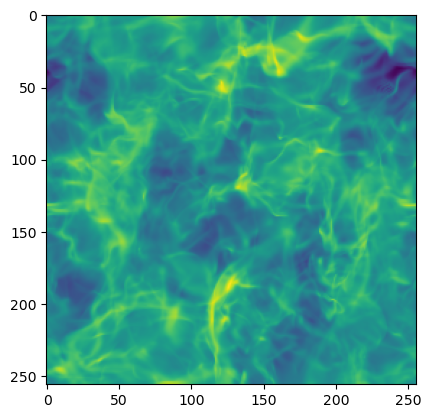

In [3]:
im = np.load(DATA_TEST_PATH + "/" + 'Turb_6.npy')[:,None,:,:]
data = DataClass(im[0,0], pbc=True)
plt.imshow(data.array.cpu().numpy())

In [4]:
wavelet_op = data.get_wavelet_op()
mean = wavelet_op.mean(data=data)
print("Mean of stl_data_type:", mean)

Mean of stl_data_type: tensor(20.3195, device='mps:0')


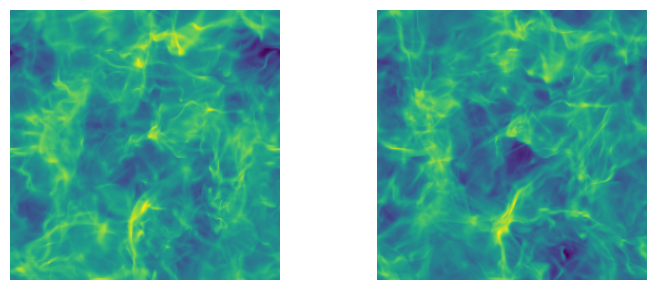

Covariance = tensor(0.0247, device='mps:0')



In [5]:
# Prepare centralized data for covariance tests
stl_data0 = DataClass(im[0,0]-im[0,0].mean())
stl_data1 = DataClass(im[1,0]-im[1,0].mean())

# Plot
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes = axes.ravel()
axes[0].imshow(stl_data0.array.cpu().numpy())
axes[0].axis('off')
axes[1].imshow(stl_data1.array.cpu().numpy())
axes[1].axis('off')
plt.tight_layout()
plt.show()

# Test of Cov
cov = wavelet_op.cov(stl_data0, stl_data1)
print("Covariance = " + str(cov))
print()

# test wavelet computation

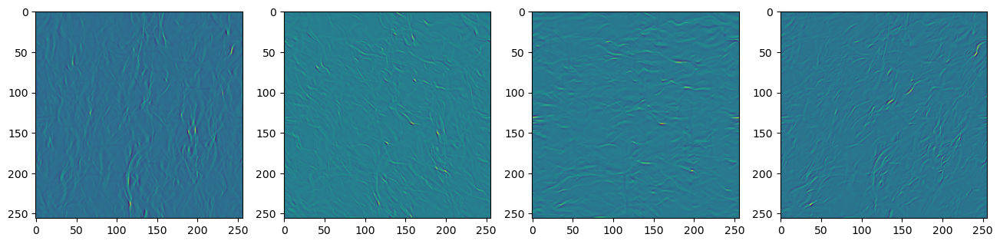

In [6]:
w_op = data.get_wavelet_op(WType="Bump-Steerable")

w_data = w_op.apply(data, j=0)

plt.figure(figsize=(16,6))
for k in range(4):
    plt.subplot(1,4,1+k)
    plt.imshow(w_data.array[k].cpu().numpy().real)

tensor(20.3149, device='mps:0')


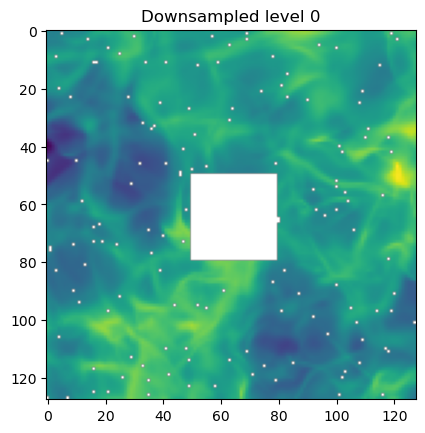

tensor(20.3148, device='mps:0')


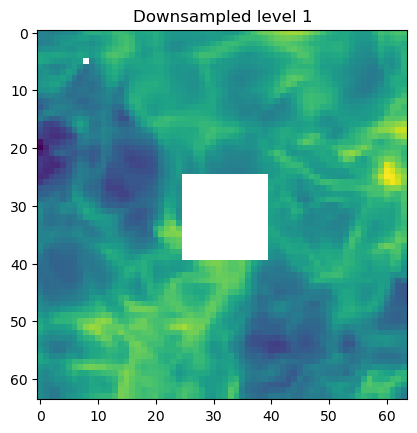

tensor(20.3147, device='mps:0')


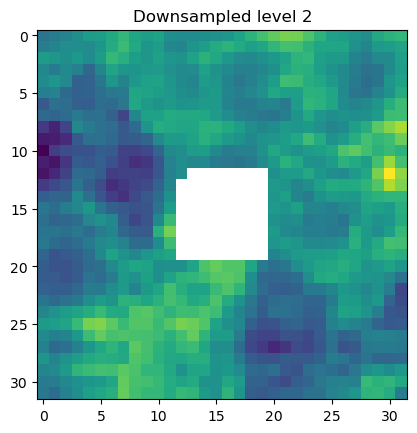

tensor(20.3146, device='mps:0')


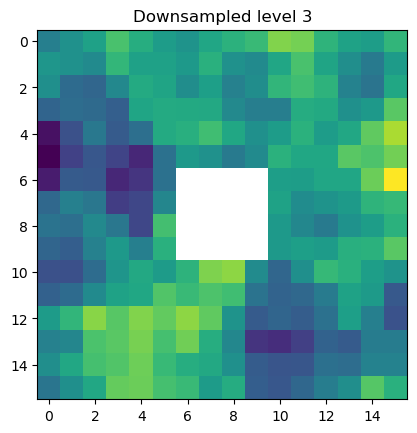

tensor(20.3139, device='mps:0')


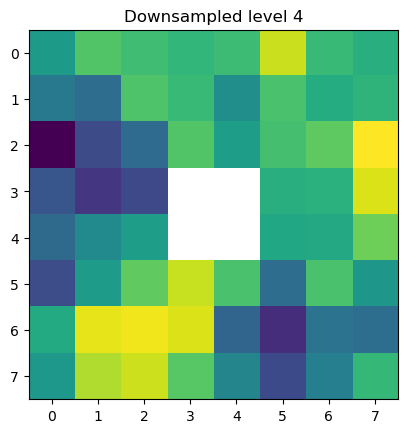

In [7]:
tmp = im[0,0].copy()
np.random.seed(32)
tmp[(np.random.rand(600)*tmp.shape[0]).astype('int'),
    (np.random.rand(600)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:80,50:80] = np.nan

l_data = DataClass(tmp[:128,:128], pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.33)

for dg in range(5):
    print(torch.nanmean(w_op.downsample(l_data, dg_out=dg, inplace=False).array))
    plt.imshow(w_op.downsample(l_data, dg_out=dg, inplace=False).array.cpu())
    plt.title("Downsampled level "+str(dg))
    plt.show()

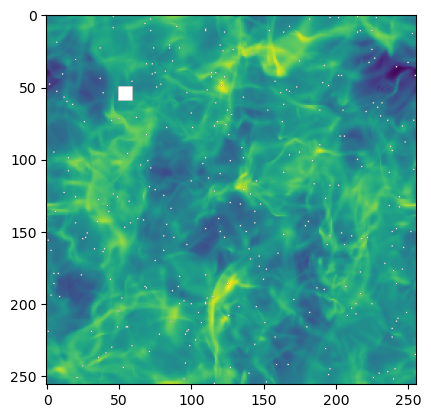

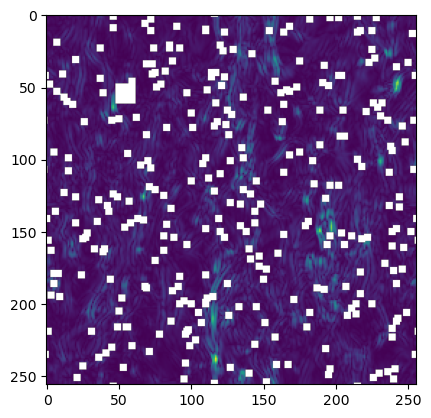

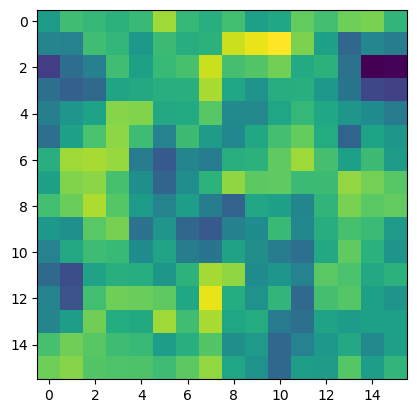

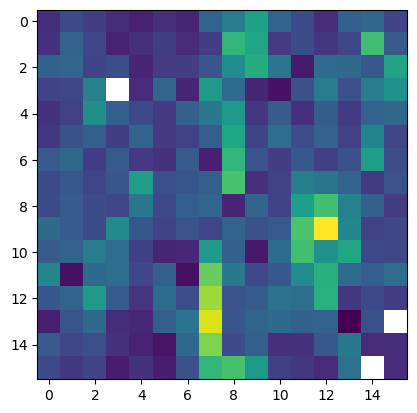

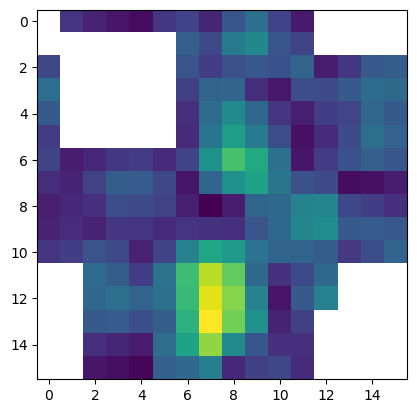

In [8]:
tmp = im[0,0].copy()
np.random.seed(32)
tmp[(np.random.rand(300)*tmp.shape[0]).astype('int'),
    (np.random.rand(300)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:60,50:60] = np.nan

plt.imshow(tmp), plt.show()

l_data = DataClass(tmp, pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.5)

w_data = w_op.apply(l_data, j=0)
plt.imshow(w_data[0].modulus(inplace=False).array.cpu().numpy()), plt.show()


j = 4

plt.imshow(w_op.downsample(l_data, dg_out=j, inplace=False).modulus(inplace=False).array.cpu().numpy()), plt.show()


w_data = w_op.downsample(w_data.modulus(inplace=False), dg_out=j, inplace=True)
plt.imshow(w_data[0].modulus().array.cpu().numpy()), plt.show()

w_data = w_op.apply(w_data, j=j)
plt.imshow(w_data[0,0].modulus().array.cpu().numpy())
plt.show()

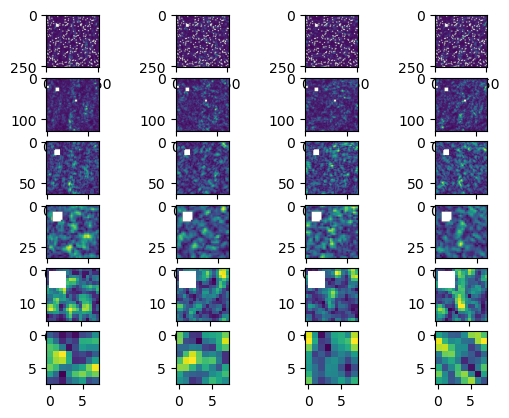

In [9]:
tmp = im[0,0].copy()
np.random.seed(27)
tmp[(np.random.rand(300)*tmp.shape[0]).astype('int'),
    (np.random.rand(300)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:60,50:60] = np.nan

l_data = DataClass(tmp, pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.33)


for j in range(w_op.J):
    w_data = w_op.apply(l_data, j=j)
    for k in range(w_op.L):
        plt.subplot(w_op.J,w_op.L,1+k+w_op.L*j)
        plt.imshow(w_data[k].modulus().array.cpu().numpy())
        
    w_op.downsample(l_data, dg_out=j+1, inplace=True) if j < w_op.J-1 else None

In [10]:
l_data = DataClass(im[0,0], pbc=True)
l_data_nan = DataClass(tmp, pbc=True)

st_op = l_data.get_ST_op()
st_op_nan = l_data_nan.get_ST_op(downsample_nan_weight_threshold=0.33, 
                                 replace_nan_value=torch.nan)

st_data_nan = st_op_nan.apply(l_data_nan, compute_PS=False)
st_data = st_op.apply(l_data)

/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


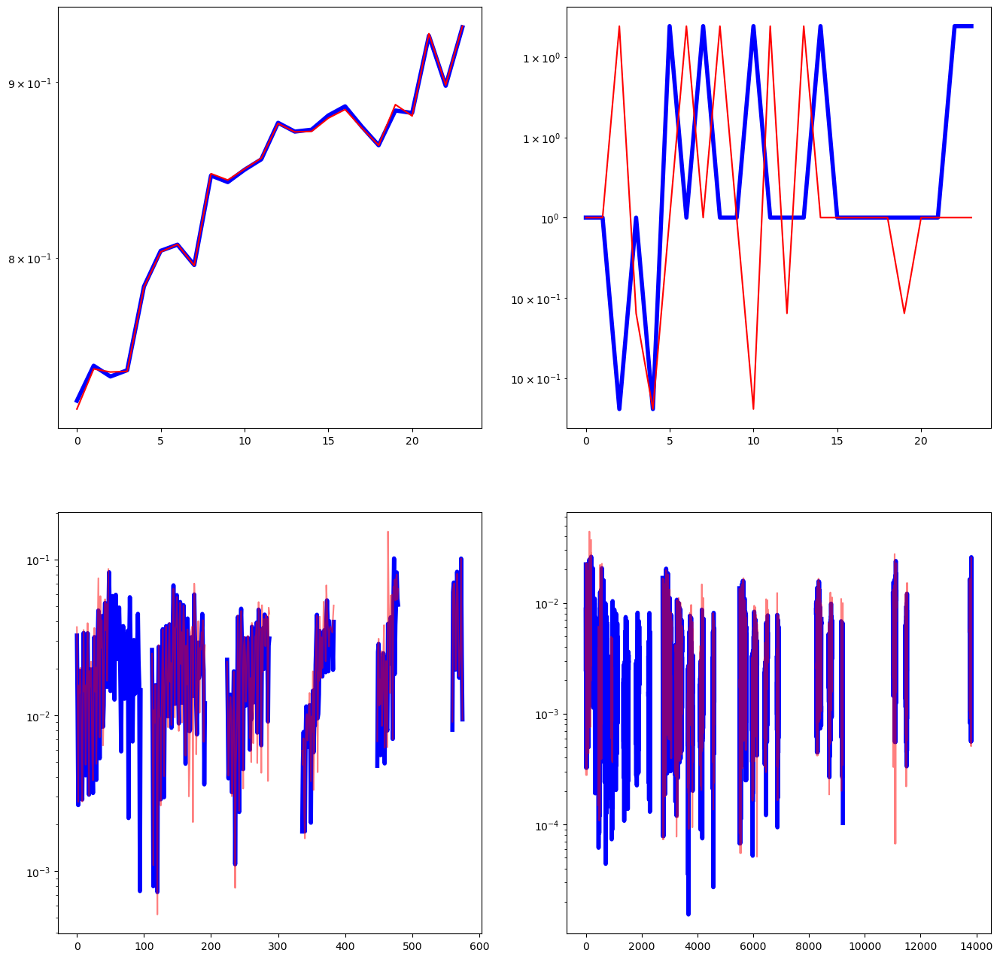

In [11]:
plt.figure(figsize=(16,16))
plt.subplot(2,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S1.cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S2.cpu().numpy().flatten(),color='r')
plt.yscale('log')


plt.subplot(2,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S3.abs().cpu().numpy().flatten(),color='r', alpha=0.5)
plt.yscale('log')
plt.subplot(2,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S4.cpu().abs().numpy().flatten(),color='r', alpha=0.5)
plt.yscale('log')

# normalization

In [12]:
st_data = st_op.apply(l_data)
st_data_norm = st_op.apply(l_data, norm='store_ref')

Replacing existing var_ref in ST_Op
Replacing existing S2_ref_sqrt_chan_diag in ST_Op
Replacing existing PS_ref_sqrt_chan_diag in ST_Op
Replacing existing var_ref in ST_Op
Replacing existing S2_ref_sqrt_chan_diag in ST_Op
Replacing existing PS_ref_sqrt_chan_diag in ST_Op


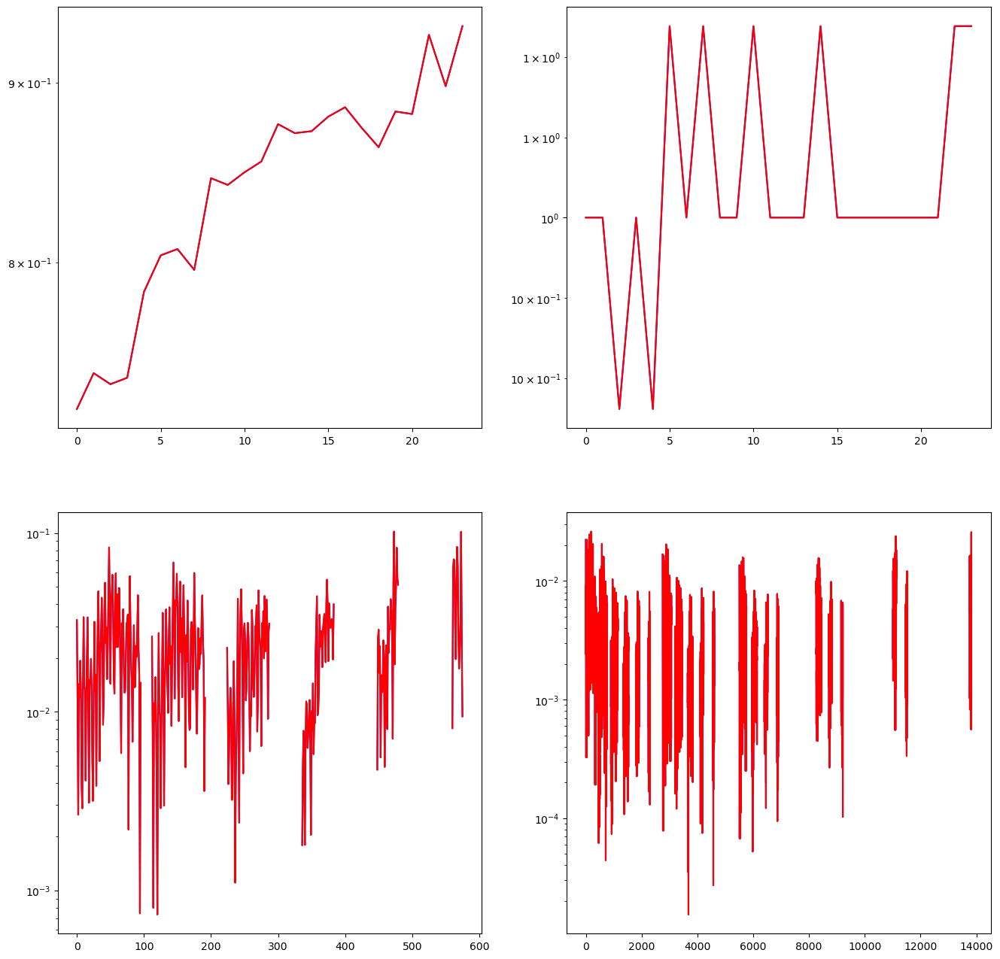

In [13]:
plt.figure(figsize=(16,16))
plt.subplot(2,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S1.cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S2.cpu().numpy().flatten(),color='r')
plt.yscale('log')

plt.subplot(2,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S3.abs().cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(),color='b')
plt.plot(st_data_norm.S4.cpu().abs().numpy().flatten(),color='r')
plt.yscale('log')

# PBC = False

Warning! Data with shape (8, 8) too small to be cropped with border 4. Using border=3 instead.


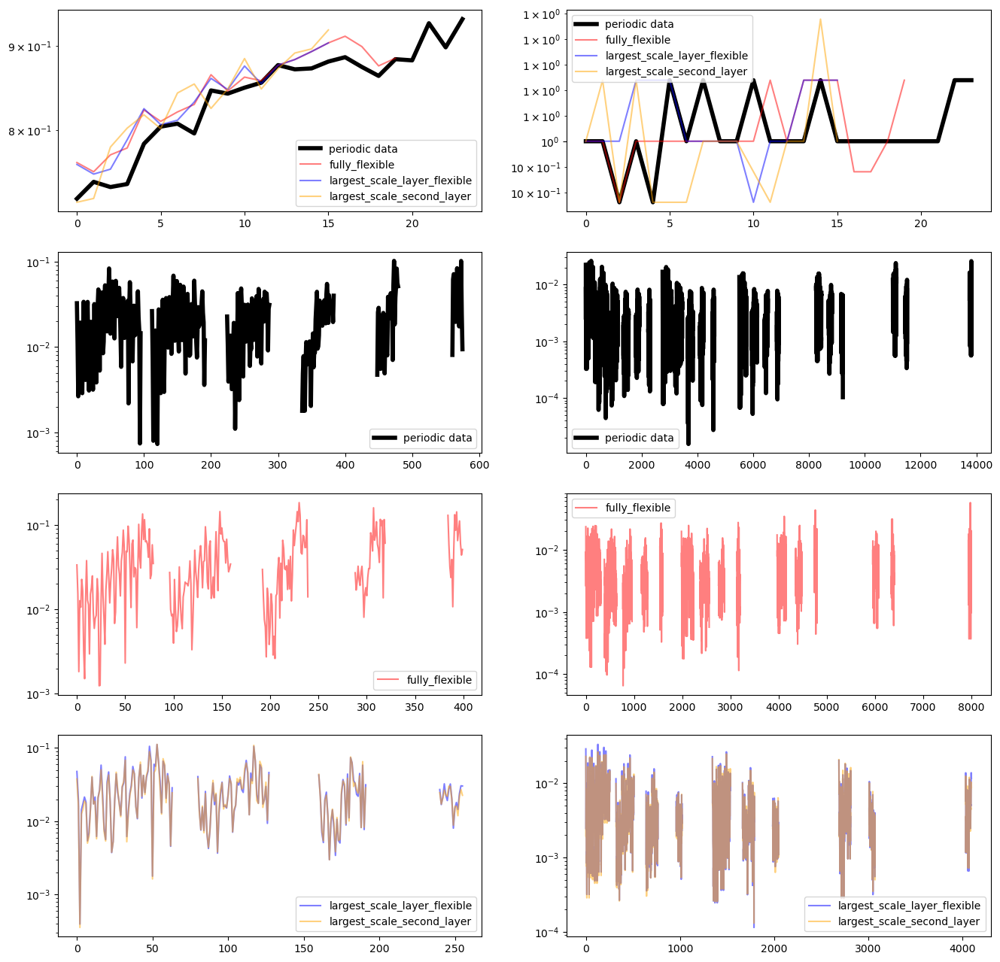

In [14]:
from STL_main.STL_2D_Kernel_Torch import WaveletOperator2Dkernel_torch as WO

l_data = DataClass(im[0,0], pbc=True)
l_data_npbc = DataClass(im[0,0,:128,:128], pbc=False)

st_op = l_data.get_ST_op()
st_data = st_op.apply(l_data)

plt.figure(figsize=(16,16))

plt.subplot(4,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(), color='black', lw=4, label='periodic data')

plt.subplot(4,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(), color='black', lw=4, label='periodic data')

plt.subplot(4,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(), color='black', lw=4, label='periodic data')
plt.yscale('log')
plt.legend()

plt.subplot(4,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(), color='black', lw=4, label='periodic data')
plt.yscale('log')
plt.legend()

colors = {'fully_flexible': 'r',
          'largest_scale_layer_flexible': 'blue',
          'largest_scale_second_layer': 'orange'}

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    
    st_op_npbc = l_data_npbc.get_ST_op(
        J=5 if method_name == 'fully_flexible' else 4,
        get_crop_border_size_method=get_crop_border_size_method)
    st_data_npbc = st_op_npbc.apply(l_data_npbc)

    plt.subplot(4,2,1)
    plt.plot(st_data_npbc.S1.cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,2)
    plt.plot(st_data_npbc.S2.cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,7 if method_name != 'fully_flexible' else 5)
    plt.plot(st_data_npbc.S3.abs().cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,8 if method_name != 'fully_flexible' else 6)
    plt.plot(st_data_npbc.S4.cpu().abs().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

plt.show()

# simple synthesis

In [15]:
seed = 42

def plot_synthesized_and_target(u, target):

    plt.figure(figsize=(10,10))
    plt.subplot(2,2,1)
    plt.imshow(u[0].cpu().numpy(), cmap='plasma')
    plt.colorbar(shrink=0.5)
    plt.axis('off')
    plt.title('Synthetised #0')
    plt.subplot(2,2,2)
    
    plt.imshow(target, cmap='plasma')
    plt.colorbar(shrink=0.5)
    plt.axis('off')
    plt.title('Target')

    fft1 = np.abs(np.fft.fftshift(np.fft.fft2(u[0].cpu().numpy())))
    fft2 = np.abs(np.fft.fftshift(np.fft.fft2(target)))

    q = 1e-2
    vmax = max(np.nanquantile(fft1, 1-q), np.nanquantile(fft2, 1-q))
    vmin = min(np.nanquantile(fft1, q),   np.nanquantile(fft2, q))

    if not np.isnan(vmax):
        plt.figure(figsize=(10,10))
        plt.subplot(2,2,1)
        plt.imshow(fft1, cmap='plasma', norm='log', vmin=vmin, vmax=vmax)
        plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('FFT Synthetised #0 Fourier')
        plt.subplot(2,2,2)
        plt.imshow(fft2, cmap='plasma', norm='log', vmin=vmin, vmax=vmax)
        plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('Target Fourier')
        plt.show()

    plt.figure(figsize=(16,4))
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.imshow(u[k].cpu().numpy(), cmap='plasma')
        plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('Synthetised #%d'%(k))

In [16]:
from STL_main.Synthesis import synthesize_from_maps

u0 = synthesize_from_maps(
    DataClass(im[0,0], pbc=True),
    pbc_running=True,
    nbatch=4,
    max_iter=100,
    prefilter_Nyquist=True,
    seed=seed,
)

Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 256, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 3986 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 3.356716e+03
[LBFGS] iter 20, loss = 2.897843e+01
[LBFGS] iter 30, loss = 8.644119e+00
[LBFGS] iter 40, loss = 2.925628e+00
[LBFGS] iter 50, loss = 1.234104e+00
[LBFGS] iter 60, loss = 6.435171e-01
[LBFGS] iter 70, loss = 4.337679e-01
[LBFGS] iter 80, loss = 2.975208e-01
[LBFGS] iter 90, loss = 2.286019e-01
[LBFGS] iter 100, loss = 1.792380e-01
108 iterations of synthesis.
Execution time: 72.538 s


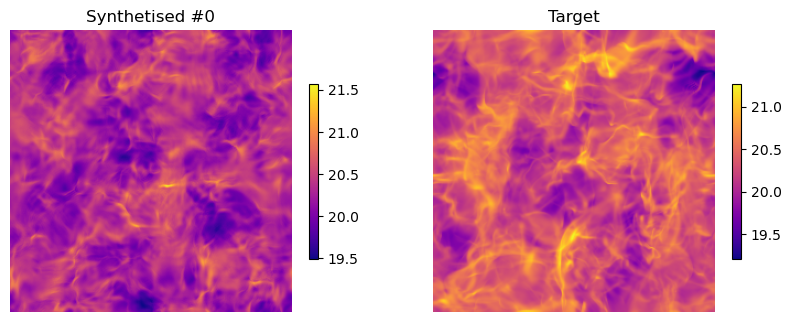

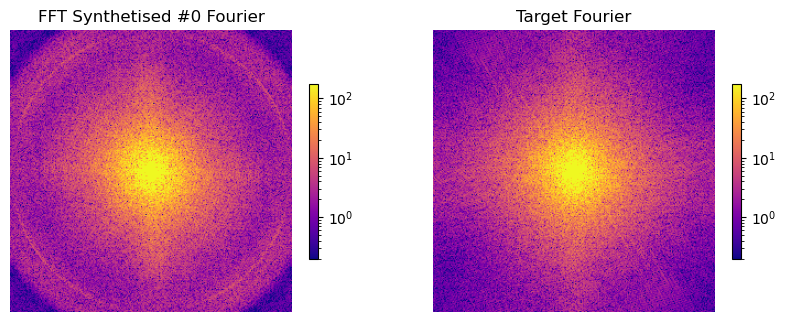

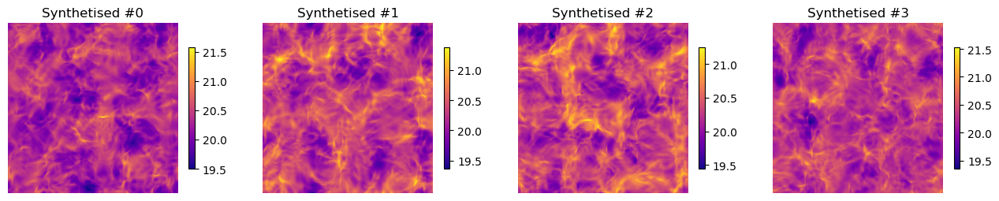

In [17]:
plot_synthesized_and_target(u0, im[0,0])

# multichannel synthesis

In [18]:
target_multi = np.stack([im[0,0], (im[0,0]-im[0,0].mean(keepdims=True))**2])
target_multi -= target_multi.mean(axis=(1,2), keepdims=True)
target_multi = DataClass(target_multi, pbc=True)
st_op = target_multi.get_ST_op()

In [19]:
compute_cross_matrix = torch.tensor([[1, 1], [0, 1]], dtype=torch.bool)
compute_cross_matrix

tensor([[ True,  True],
        [False,  True]])

In [20]:
u1 = optimize_from_maps(
        target=target_multi,
        st_op_target=st_op,
        st_op_running=st_op,
        pbc_running=True,
        compute_cross_matrix=compute_cross_matrix,        
        nbatch=4,
        prefilter_Nyquist=True,
        max_iter=100,
        lr=1.0,
        history_size=50,
        print_iter=10,
        verbose=True,
        seed=seed,
    )

Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 2, 256, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 15828 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 1.288967e+03
[LBFGS] iter 20, loss = 8.637080e+01
[LBFGS] iter 30, loss = 2.170284e+01
[LBFGS] iter 40, loss = 8.872741e+00
[LBFGS] iter 50, loss = 4.914572e+00
[LBFGS] iter 60, loss = 3.305577e+00
[LBFGS] iter 70, loss = 2.471078e+00
[LBFGS] iter 80, loss = 1.864415e+00
[LBFGS] iter 90, loss = 1.484184e+00
[LBFGS] iter 100, loss = 1.222430e+00
107 iterations of synthesis.
Execution time: 160.772 s


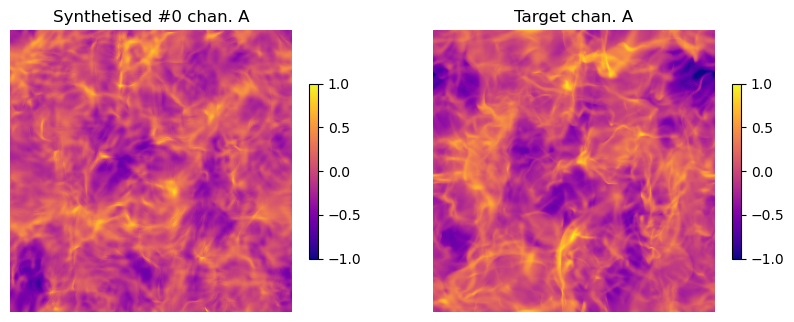

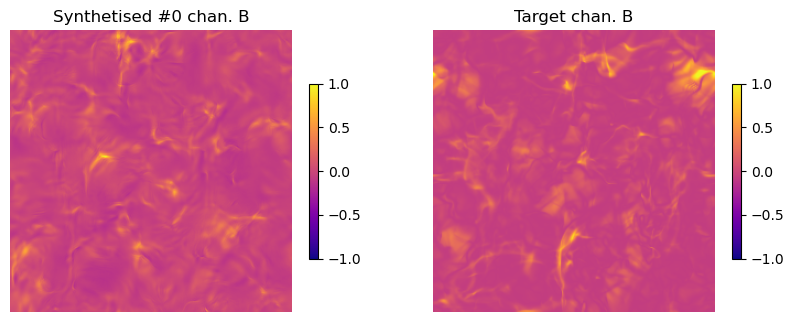

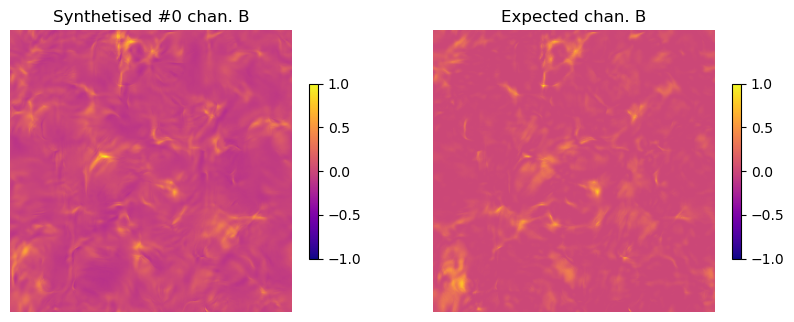

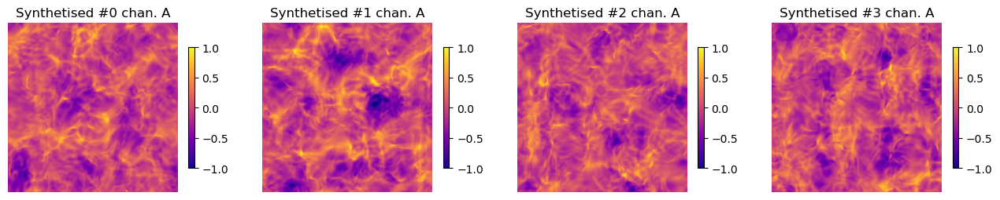

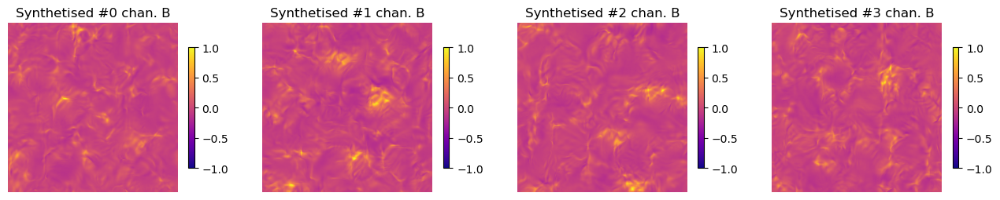

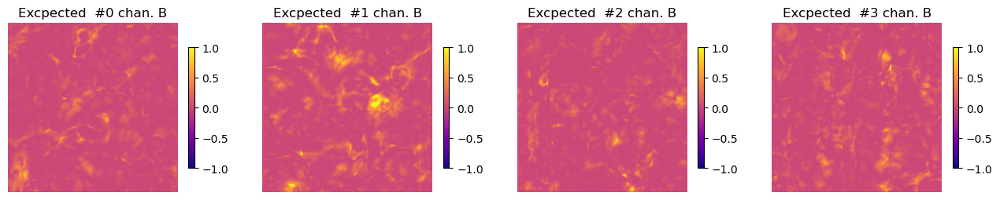

In [21]:
amp = 1
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(u1[0,0].cpu().numpy(), cmap='plasma', vmin=-amp, vmax=amp)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Synthetised #0 chan. A')
plt.subplot(2,2,2)
plt.imshow(target_multi.array[0].cpu().numpy(), cmap='plasma', vmin=-amp, vmax=amp)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target chan. A')
plt.show()

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(u1[0,1].cpu().numpy(), cmap='plasma', vmin=-amp, vmax=amp)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Synthetised #0 chan. B')
plt.subplot(2,2,2)
plt.imshow(target_multi.array[1].cpu().numpy(), cmap='plasma', vmin=-amp, vmax=amp)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target chan. B')
plt.show()

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(u1[0,1].cpu().numpy(), cmap='plasma', vmin=-amp, vmax=amp)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Synthetised #0 chan. B')
plt.subplot(2,2,2)
plt.imshow(u1[0,0].cpu().numpy()**2, cmap='plasma', vmin=-amp, vmax=amp)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Expected chan. B')
plt.show()

plt.figure(figsize=(16,4))
for k in range(4):
    plt.subplot(1,4,1+k)
    plt.imshow(u1[k,0].cpu().numpy(), cmap='plasma', vmin=-amp, vmax=amp)
    plt.colorbar(shrink=0.5)
    plt.axis('off')
    plt.title('Synthetised #%d chan. A'%(k))
plt.figure(figsize=(16,4))
for k in range(4):
    plt.subplot(1,4,1+k)
    plt.imshow(u1[k,1].cpu().numpy(), cmap='plasma', vmin=-amp, vmax=amp)
    plt.colorbar(shrink=0.5)
    plt.axis('off')
    plt.title('Synthetised #%d chan. B'%(k))
plt.figure(figsize=(16,4))
for k in range(4):
    plt.subplot(1,4,1+k)
    plt.imshow(u1[k,0].cpu().numpy()**2, cmap='plasma', vmin=-amp, vmax=amp)
    plt.colorbar(shrink=0.5)
    plt.axis('off')
    plt.title('Excpected  #%d chan. B'%(k))

# Synthesis with NaNs

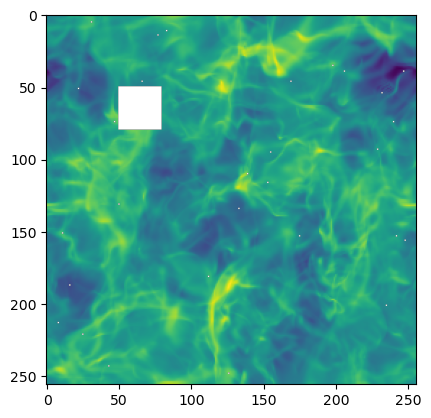

In [22]:
tmp = im[0,0].copy()
np.random.seed(seed)
tmp[(np.random.rand(30)*tmp.shape[0]).astype('int'),
    (np.random.rand(30)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:80,50:80] = np.nan
plt.imshow(tmp)
plt.show()

## Running without NaNs

In [23]:
target = DataClass(tmp, pbc=True)

u2 = optimize_from_maps(
        target=target,
        st_op_target=target.get_ST_op(),
        st_op_running=DataClass(im[0,0], pbc=True).get_ST_op(),
        pbc_running=True,
        nbatch=4,
        max_iter=100,
        prefilter_Nyquist=True,
        lr=1.0,
        history_size=50,
        print_iter=10,
        verbose=True,
        seed=seed,
    )

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256, 256)
Synthesis on 3970 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 5.467183e+02
[LBFGS] iter 20, loss = 2.292556e+01
[LBFGS] iter 30, loss = 7.636395e+00
[LBFGS] iter 40, loss = 2.566542e+00
[LBFGS] iter 50, loss = 1.403890e+00
[LBFGS] iter 60, loss = 9.532429e-01
[LBFGS] iter 70, loss = 7.269312e-01
[LBFGS] iter 80, loss = 6.154584e-01
[LBFGS] iter 90, loss = 5.464844e-01
[LBFGS] iter 100, loss = 4.958325e-01
[LBFGS] iter 110, loss = 4.607471e-01
110 iterations of synthesis.
Execution time: 69.324 s


/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1601: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


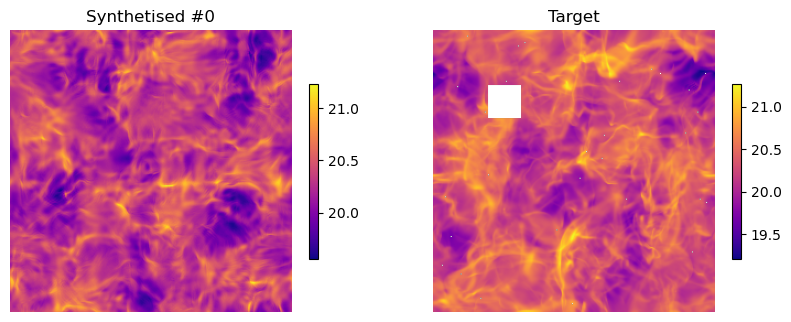

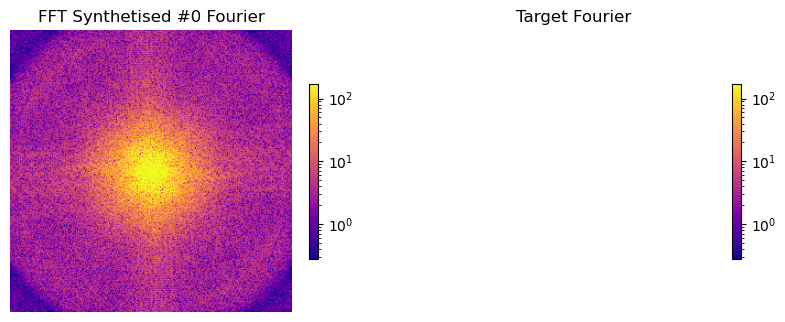

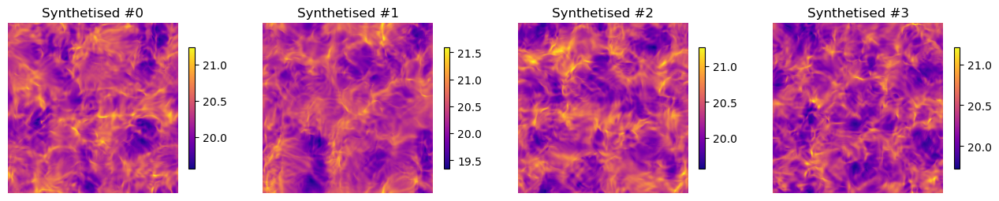

In [24]:
plot_synthesized_and_target(u2, target.array.cpu().numpy())

## Running with same NaN mask as target

In [25]:
u3 = optimize_from_maps(
        target=target,
        st_op_target=target.get_ST_op(),
        st_op_running=target.get_ST_op(replace_nan_value=None),
        pbc_running=True,
        nbatch=4,
        max_iter=100,
        prefilter_Nyquist=True,
        lr=1.0,
        history_size=50,
        print_iter=10,
        verbose=True,
        seed=seed,
    )

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256, 256)
Synthesis on 3970 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
NaN detected in the running synthesis mask, the synthesis takes it into account
[LBFGS] iter 10, loss = 5.456088e+02
[LBFGS] iter 20, loss = 2.027250e+01
[LBFGS] iter 30, loss = 4.925432e+00
[LBFGS] iter 40, loss = 1.688072e+00
[LBFGS] iter 50, loss = 9.746532e-01
[LBFGS] iter 60, loss = 6.502302e-01
[LBFGS] iter 70, loss = 4.804271e-01
[LBFGS] iter 80, loss = 3.727562e-01
[LBFGS] iter 90, loss = 3.071677e-01
[LBFGS] iter 100, loss = 2.511376e-01
108 iterations of synthesis.
Execution time: 68.350 s


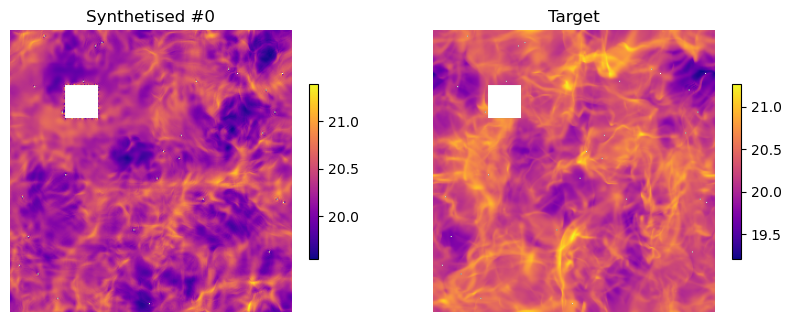

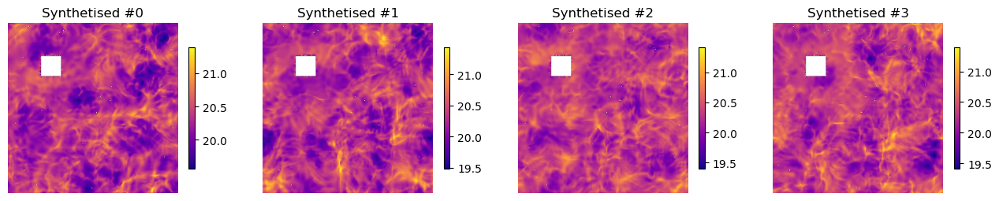

In [26]:
plot_synthesized_and_target(u3, tmp)

## Running with new NaN mask

In [27]:
new_mask = np.zeros_like(im[0,0])
new_mask[150:175,150:175] = np.nan

In [28]:
u4 = optimize_from_maps(
        target=target,
        st_op_target=target.get_ST_op(L=6),
        st_op_running=DataClass(new_mask, pbc=True).get_ST_op(replace_nan_value=None, L=6),
        pbc_running=True,
        nbatch=4,
        max_iter=100,
        prefilter_Nyquist=True,
        lr=1.0,
        history_size=50,
        print_iter=10,
        verbose=True,
        seed=seed,
    )

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256, 256)
Synthesis on 12926 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
NaN detected in the running synthesis mask, the synthesis takes it into account
[LBFGS] iter 10, loss = 9.177308e+02
[LBFGS] iter 20, loss = 3.361663e+01
[LBFGS] iter 30, loss = 9.348120e+00
[LBFGS] iter 40, loss = 4.195799e+00
[LBFGS] iter 50, loss = 2.617556e+00
[LBFGS] iter 60, loss = 1.766619e+00
[LBFGS] iter 70, loss = 1.324096e+00
[LBFGS] iter 80, loss = 1.082466e+00
[LBFGS] iter 90, loss = 9.009408e-01
[LBFGS] iter 100, loss = 7.785764e-01
108 iterations of synthesis.
Execution time: 88.937 s


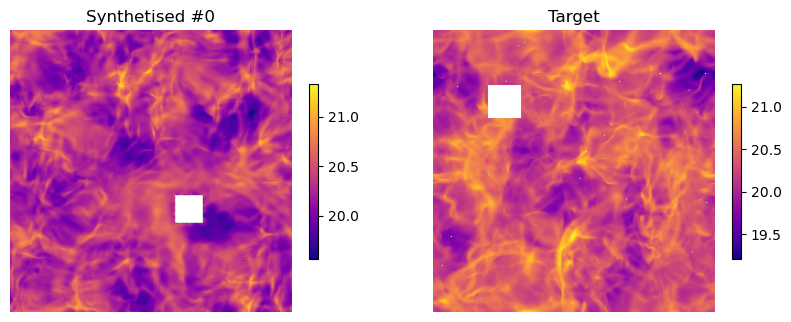

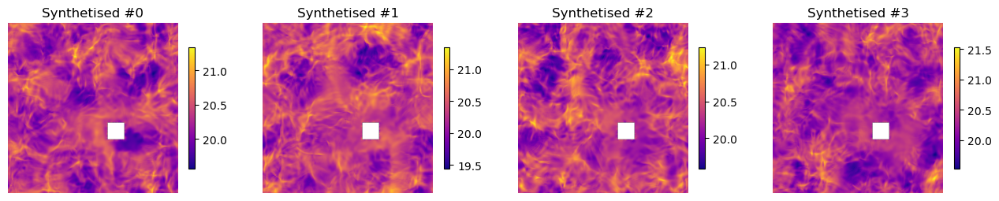

In [29]:
plot_synthesized_and_target(u4, tmp)

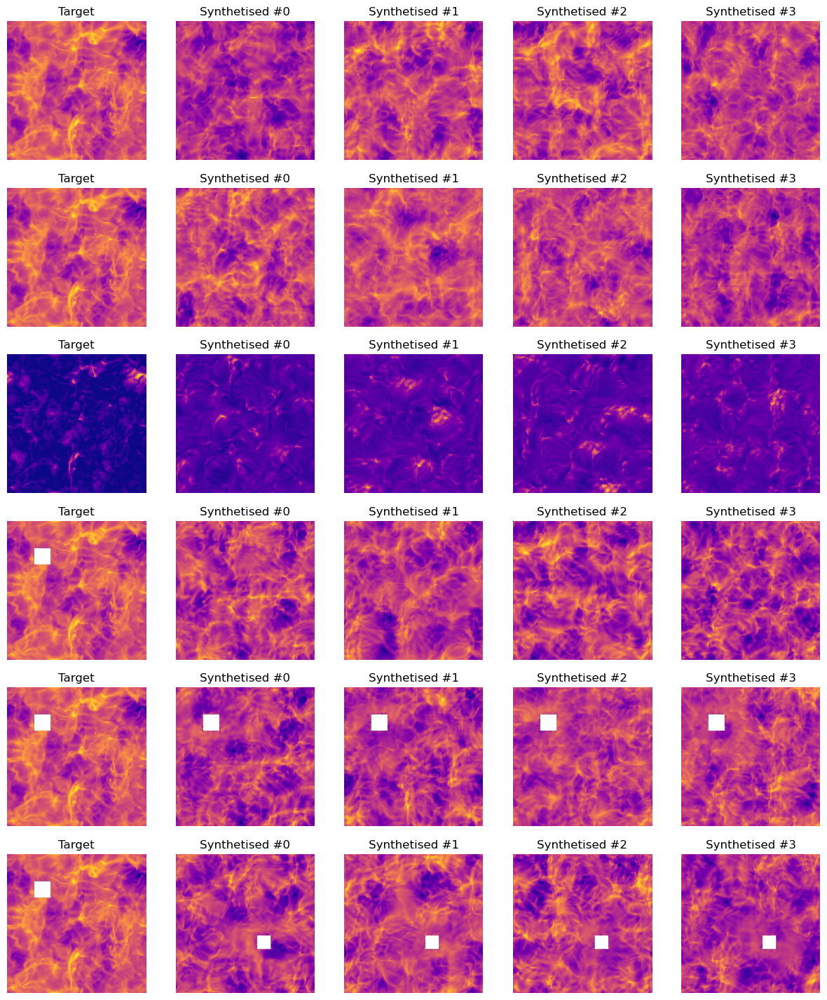

In [30]:
plt.figure(figsize=(5*3, 6*3))
for ind, (u, tgt) in enumerate(zip([u0, u1[:,0], u1[:,1], u2, u3, u4], [im[0,0], im[0,0], target_multi.array[1].cpu().numpy(), tmp, tmp, tmp])):
    plt.subplot(6,5,1 + ind*5)
    plt.imshow(tgt, cmap='plasma'), plt.axis('off')
    plt.title('Target')
    for k in range(4):
        plt.subplot(6,5,2 + k + ind*5)
        plt.imshow(u[k].cpu().numpy(), cmap='plasma')
        plt.title('Synthetised #%d'%(k))
        plt.axis('off')

if False:
    plt.savefig("nan_synthesis.png", bbox_inches='tight', dpi=100)

# synthesis with PBC = False 

In [31]:
synthesis_target_npbc_results = {}

target = DataClass(im[0,0,:128,:128], pbc=False)

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    print(method_name)
    J = 5 if method_name == 'fully_flexible' else 4

    u = optimize_from_maps(
            target=target,
            st_op_target=target.get_ST_op(
                J=J,
                get_crop_border_size_method=get_crop_border_size_method),
            st_op_running=DataClass(im[0,0,:128,:128], pbc=True).get_ST_op(J=J),
            pbc_running=True,
            nbatch=4,
            max_iter=100,
            prefilter_Nyquist=True,
            lr=1.0,
            history_size=50,
            print_iter=10,
            verbose=True,
            seed=seed,
        )

    synthesis_target_npbc_results[method_name] = u

fully_flexible
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 128, 128)
Prefiltering target to remove frequencies above Nyquist
Warning! Data with shape (8, 8) too small to be cropped with border 4. Using border=3 instead.
Synthesis on 2522 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 3.658783e+02
[LBFGS] iter 20, loss = 1.943825e+01
[LBFGS] iter 30, loss = 6.965051e+00
[LBFGS] iter 40, loss = 4.006885e+00
[LBFGS] iter 50, loss = 3.110631e+00
[LBFGS] iter 60, loss = 2.683783e+00
[LBFGS] iter 70, loss = 2.364332e+00
[LBFGS] iter 80, loss = 2.158353e+00
[LBFGS] iter 90, loss = 1.966420e+00
[LBFGS] iter 100, loss = 1.791183e+00
106 iterations of synthesis.
Execution time: 44.708 s
largest_scale_layer_flexible
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 128, 128)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 1474 ST coefficients
Prefilt

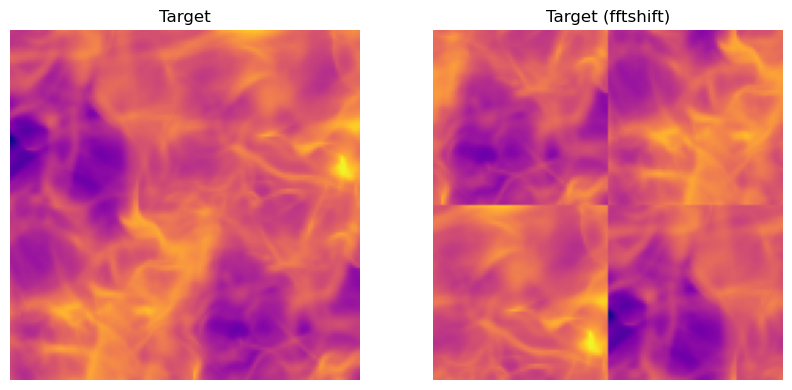

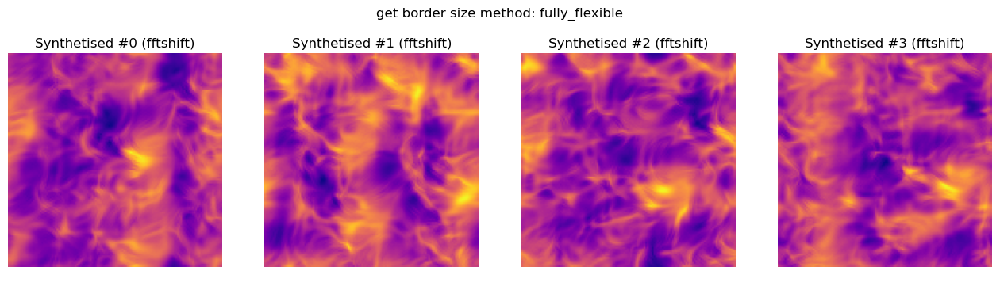

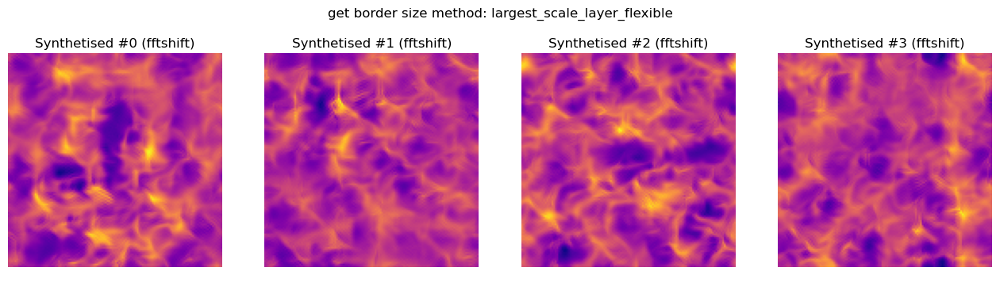

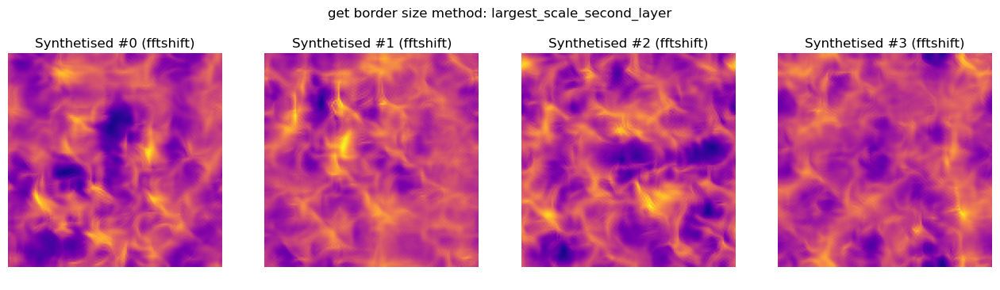

In [32]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(im[0,0,:128,:128], cmap='plasma')
#plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.imshow(np.fft.fftshift(im[0,0,:128,:128]), cmap='plasma')
#plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target (fftshift)')

for method_name, u in synthesis_target_npbc_results.items():

    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.imshow(np.fft.fftshift(u[k].cpu().numpy()), cmap='plasma')
        #plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('Synthetised #%d (fftshift)'%(k))

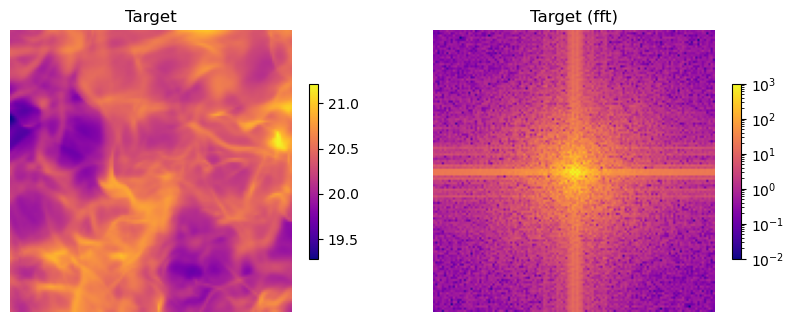

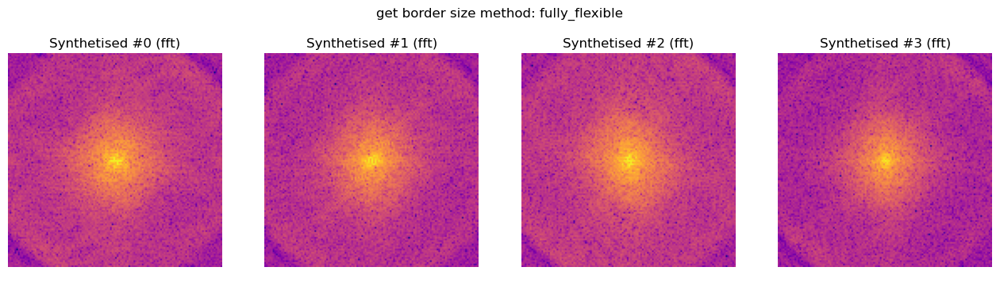

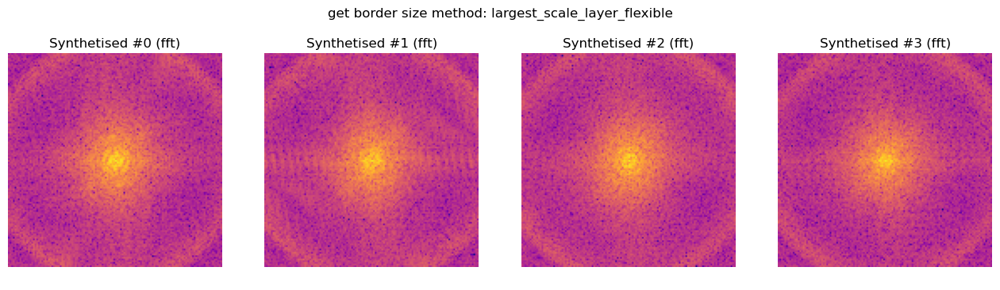

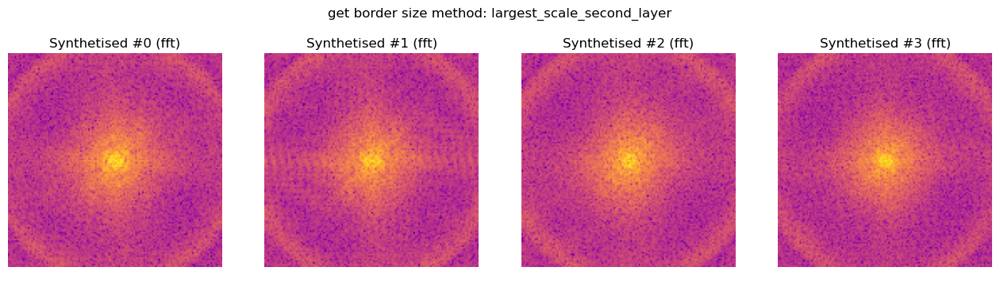

In [33]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(im[0,0,:128,:128], cmap='plasma')
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.imshow(np.abs(np.fft.fftshift(np.fft.fft2(im[0,0,:128,:128]))), cmap='plasma', norm='log', vmin=1e-2, vmax=1e3)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target (fft)')

for method_name, u in synthesis_target_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.imshow(np.abs(np.fft.fftshift(np.fft.fft2(u[k].cpu().numpy()))), cmap='plasma', norm='log', vmin=1e-2, vmax=1e3)
        #plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('Synthetised #%d (fft)'%(k))

In [34]:
synthesis_target_running_npbc_results = {}

target = DataClass(im[0,0,:128,:128], pbc=False)

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    print(method_name)
    J = 5 if method_name == 'fully_flexible' else 4

    st_op = target.get_ST_op(J=J, get_crop_border_size_method=get_crop_border_size_method)

    u = optimize_from_maps(
            target=target,
            st_op_target=st_op,
            st_op_running=st_op,
            pbc_running=False,
            nbatch=4,
            max_iter=150,
            lr=1.0,
            history_size=50,
            print_iter=10,
            verbose=True,
            seed=seed,
        )

    synthesis_target_running_npbc_results[method_name] = u

fully_flexible
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 128, 128)
Prefiltering target to remove frequencies above Nyquist
Warning! Data with shape (8, 8) too small to be cropped with border 4. Using border=3 instead.
Synthesis on 2522 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 4.086921e+02
[LBFGS] iter 20, loss = 2.065110e+01
[LBFGS] iter 30, loss = 8.745361e+00
[LBFGS] iter 40, loss = 5.146614e+00
[LBFGS] iter 50, loss = 3.609865e+00
[LBFGS] iter 60, loss = 2.589361e+00
[LBFGS] iter 70, loss = 2.000885e+00
[LBFGS] iter 80, loss = 1.571844e+00
[LBFGS] iter 90, loss = 1.249569e+00
[LBFGS] iter 100, loss = 1.033108e+00
[LBFGS] iter 110, loss = 8.979476e-01
[LBFGS] iter 120, loss = 7.939751e-01
[LBFGS] iter 130, loss = 7.053739e-01
[LBFGS] iter 140, loss = 6.329703e-01
[LBFGS] iter 150, loss = 5.613254e-01
155 iterations of synthesis.
Execution time: 69.881 s
largest_scale_layer_flexible
R

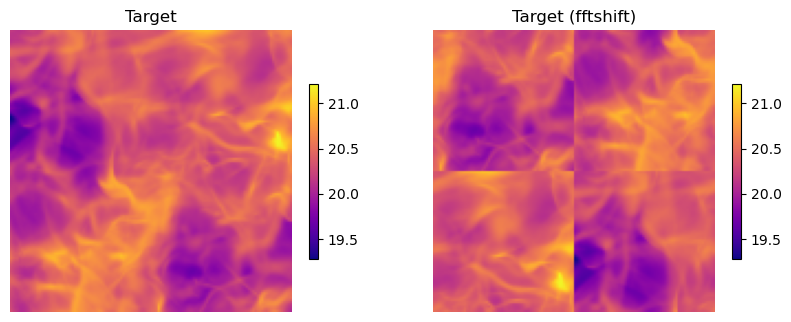

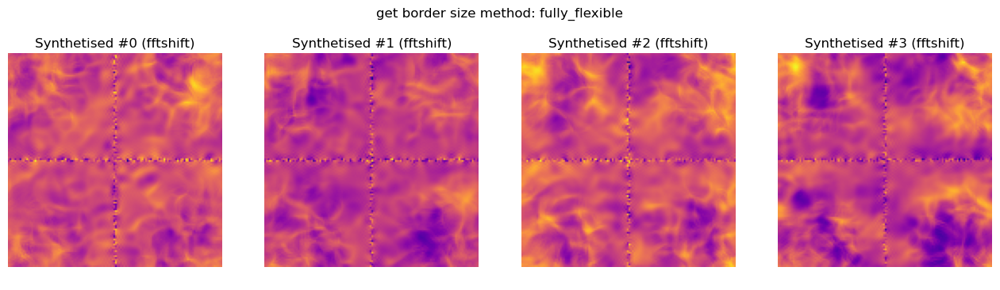

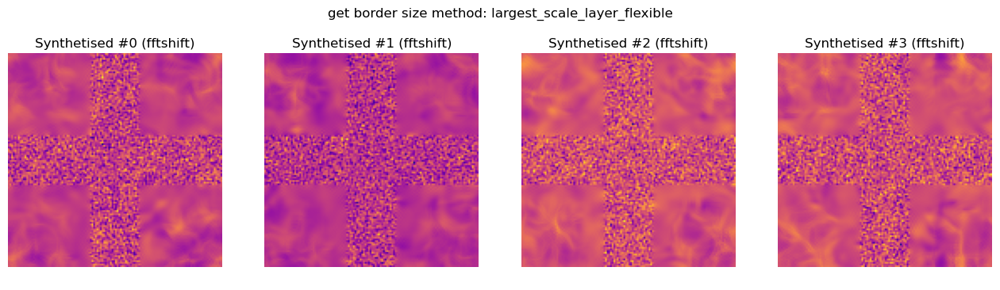

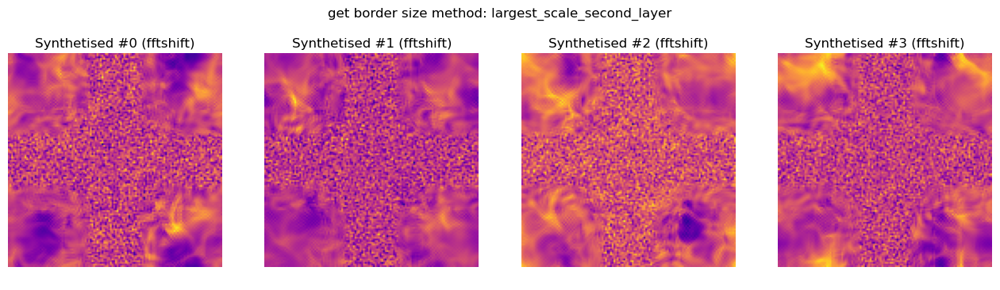

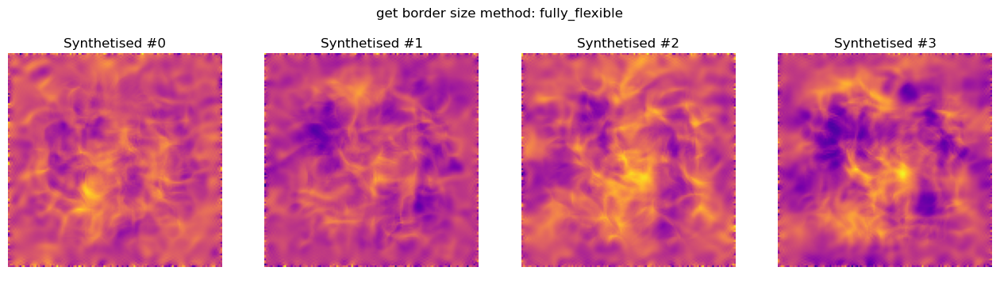

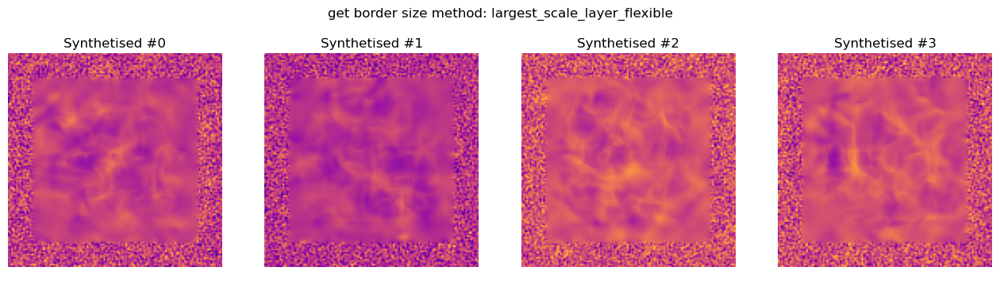

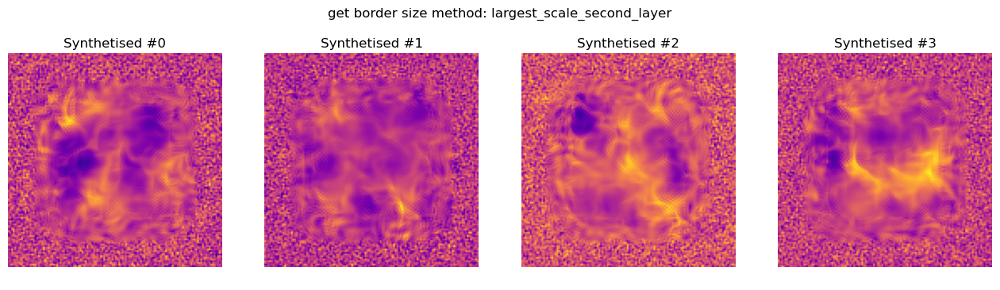

In [35]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(im[0,0,:128,:128], cmap='plasma')
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.imshow(np.fft.fftshift(im[0,0,:128,:128]), cmap='plasma')
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target (fftshift)')

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.imshow(np.fft.fftshift(u[k].cpu().numpy()), cmap='plasma')
        #plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('Synthetised #%d (fftshift)'%(k))

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.imshow(u[k].cpu().numpy(), cmap='plasma')
        #plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('Synthetised #%d'%(k))

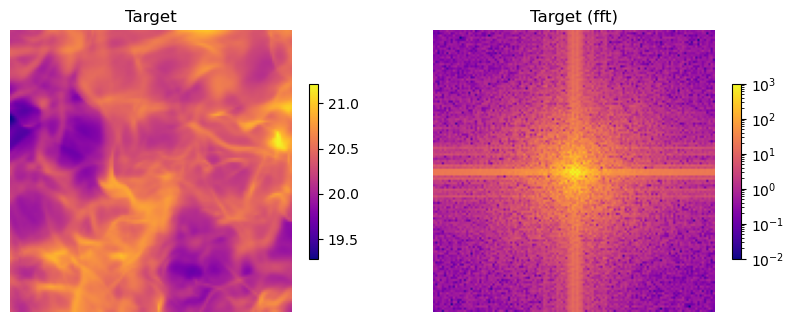

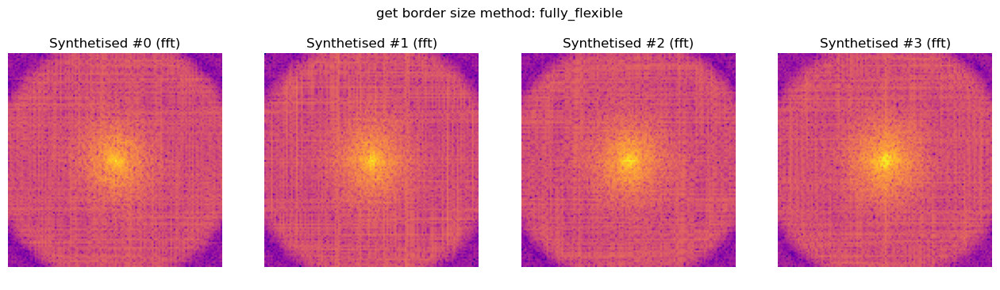

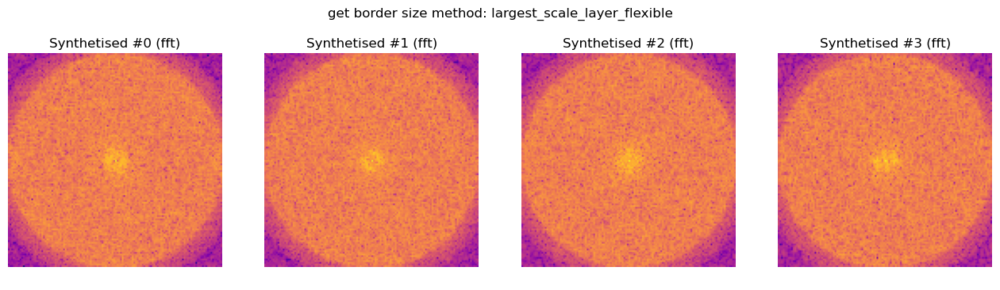

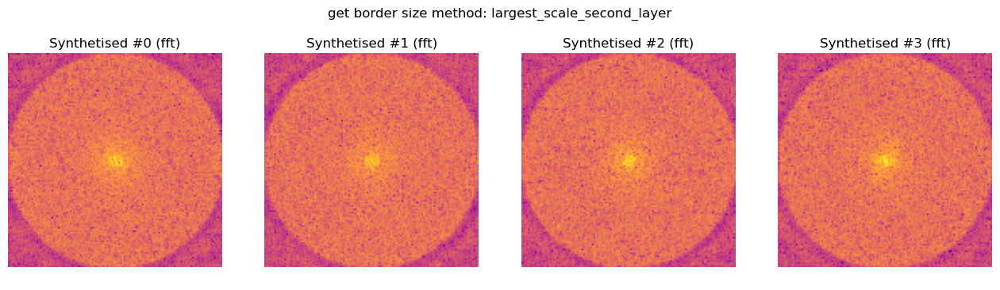

In [36]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(im[0,0,:128,:128], cmap='plasma')
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.imshow(np.abs(np.fft.fftshift(np.fft.fft2(im[0,0,:128,:128]))), cmap='plasma', norm='log', vmin=1e-2, vmax=1e3)
plt.colorbar(shrink=0.5)
plt.axis('off')
plt.title('Target (fft)')

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.imshow(np.abs(np.fft.fftshift(np.fft.fft2(u[k].cpu().numpy()))), cmap='plasma', norm='log', vmin=1e-2, vmax=1e3)
        #plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.title('Synthetised #%d (fft)'%(k))

### Littlewood-Paley

In [37]:
data = np.load(str(DATA_TEST_PATH) + "/" + "Turb_6.npy")[0]
stl_data = DataClass(data, pbc=True)
Wave_Op = stl_data.get_wavelet_op()
Wave_Op._get_smooth_kernel(device=stl_data.device, dtype=stl_data.dtype)

tensor([[ 0.0024, -0.0028, -0.0240, -0.0240, -0.0028,  0.0024],
        [-0.0028,  0.0032,  0.0278,  0.0278,  0.0032, -0.0028],
        [-0.0240,  0.0278,  0.2425,  0.2425,  0.0278, -0.0240],
        [-0.0240,  0.0278,  0.2425,  0.2425,  0.0278, -0.0240],
        [-0.0028,  0.0032,  0.0278,  0.0278,  0.0032, -0.0028],
        [ 0.0024, -0.0028, -0.0240, -0.0240, -0.0028,  0.0024]],
       device='mps:0')

In [38]:
print(Wave_Op.J)
print(Wave_Op._wav_kernel.shape)
print(Wave_Op._smooth_kernel.shape)

6
torch.Size([1, 4, 5, 5])
torch.Size([6, 6])


The objective is to calculate the transfer functions $T_n(f)$ in order to analyze the overlaps and gaps in the Fourier space using wavelets.

$$T_n(f) = \hat{K}(2^n \cdot f) \times \prod_{i=0}^{n-1} \hat{H}(2^i \cdot f)$$

Tip: Insert $2^n -1$ zeros between each sample, then pad with zeros to the full resolution size.

In [39]:
import torch.nn.functional as F

K_real = []
H_real = []
K = Wave_Op._wav_kernel.shape[-1]
H = Wave_Op._smooth_kernel.shape[-1]
N, M = stl_data.N0

for j in range(Wave_Op.J):
    step = 2**j
    Kd = torch.zeros((Wave_Op.L, K*step, K*step), device=Wave_Op._wav_kernel.device, dtype=Wave_Op._wav_kernel.dtype)
    Kd[:, ::step, ::step] = Wave_Op._wav_kernel.squeeze(0)

    Hd = torch.zeros((H*step, H*step), device=Wave_Op._smooth_kernel.device, dtype=Wave_Op._smooth_kernel.dtype)
    Hd[::step, ::step] = Wave_Op._smooth_kernel

    K_pad_h = N - Kd.shape[-2]
    K_pad_w = M - Kd.shape[-1]

    Kd = F.pad(Kd, (0, K_pad_w, 0, K_pad_h))  

    H_pad_h = N - Hd.shape[-2]
    H_pad_w = M - Hd.shape[-1]
    Hd = F.pad(Hd, (0, H_pad_w, 0, H_pad_h))

    K_real.append(Kd)
    H_real.append(Hd)

K_real = torch.stack(K_real, dim=0) # Shape: [J, L, N, M]
H_real = torch.stack(H_real, dim=0) # Shape: [J, N, M]

K_fft = torch.fft.fft2(K_real)  # Shape: [J, L, N, M]
H_fft = torch.fft.fft2(H_real)  # Shape: [J, N, M]

In [40]:
H_cumprod = torch.cumprod(H_fft.abs(), dim=0)  # [J, N, M]
H_prod = torch.ones_like(H_cumprod)
H_prod[1:] = H_cumprod[:-1]
T = K_fft * H_prod[:, None, :, :]
T = torch.fft.fftshift(T, dim=(-2, -1))

In [41]:
print(K_fft.shape)
print(H_fft.shape)
print(T.shape)

torch.Size([6, 4, 256, 256])
torch.Size([6, 256, 256])
torch.Size([6, 4, 256, 256])


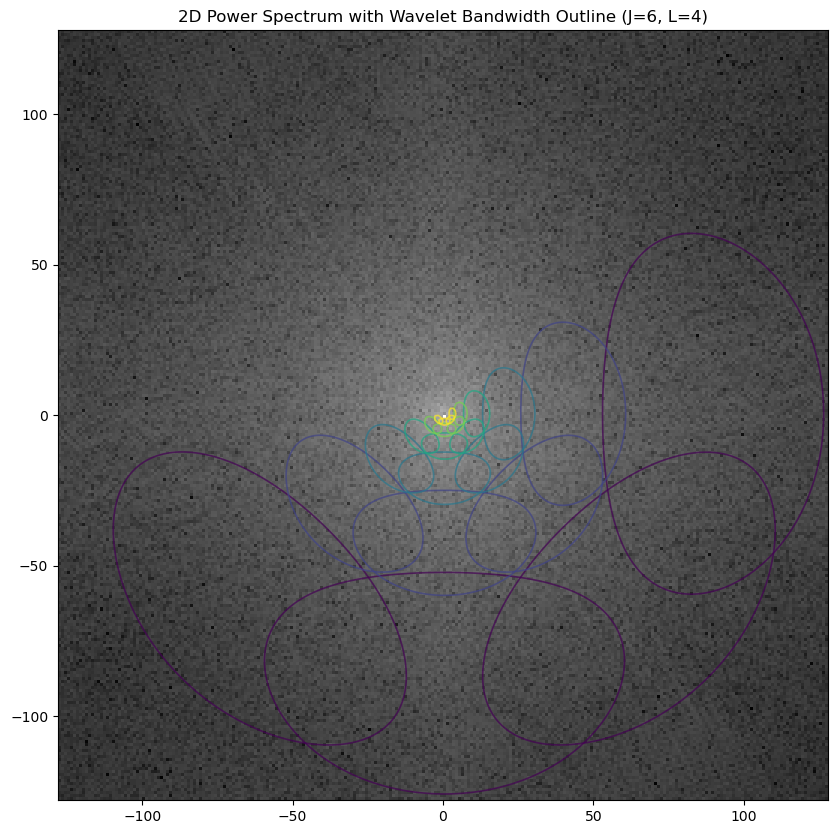

In [42]:
power_spectrum_2d = torch.fft.fftshift(torch.fft.fft2(stl_data.array)).abs()**2

plt.figure(figsize=(12, 10))

plt.imshow(torch.log10(power_spectrum_2d).cpu().numpy(), cmap='gray', 
           extent=[-stl_data.N0[0]//2, stl_data.N0[0]//2, -stl_data.N0[1]//2, stl_data.N0[1]//2])

colors = plt.cm.viridis(np.linspace(0, 1, Wave_Op.J))

for j in range(Wave_Op.J):
    for l in range(Wave_Op.L):

        wav = T[j, l]
        wav_mod = torch.abs(wav).cpu().numpy()

        plt.contour(wav_mod, levels=[0.5*wav_mod.max()], 
                    colors=[colors[j]], 
                    extent=[-stl_data.N0[0]//2, stl_data.N0[0]//2, -stl_data.N0[1]//2, stl_data.N0[1]//2],
                    linewidths=1.2, alpha=0.7)
    
plt.title(f"2D Power Spectrum with Wavelet Bandwidth Outline (J={Wave_Op.J}, L={Wave_Op.L})")
plt.show()

To verify Littlewood-Paley's condition, the ratio below must be constant and equal to 1 for all frequencies.

$$R(\mathbf{\omega}) = \frac{\sum_{j, \theta} S_I(\mathbf{\omega}) \cdot |\hat{\psi}_{j, \theta}(\mathbf{\omega})|^2}{S_I(\mathbf{\omega})}$$

Text(0.5, 1.0, 'Energy Recovery Ratio in Fourier Space')

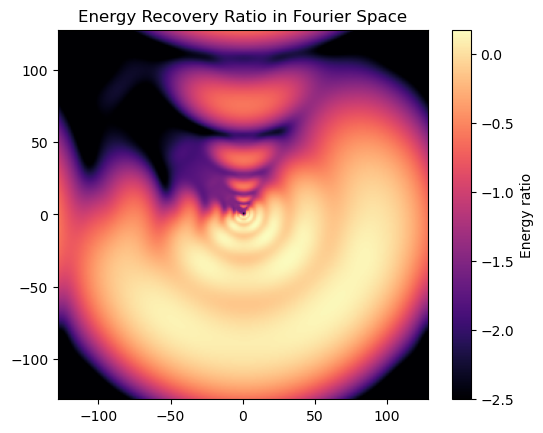

In [43]:
energy_sum = torch.zeros_like(power_spectrum_2d)

for j in range(Wave_Op.J):
    for l in range(Wave_Op.L):
        energy_sum += power_spectrum_2d * (torch.abs(T[j,l])**2)

eps = 1e-12
energy_recover_ratio = energy_sum / (power_spectrum_2d)

plt.imshow(
    np.log10(energy_recover_ratio.cpu().numpy()),
    origin='lower',
    cmap='magma',
    extent=[-stl_data.N0[0]//2, stl_data.N0[0]//2, -stl_data.N0[1]//2, stl_data.N0[1]//2],
    vmin=-2.5
)
plt.colorbar(label="Energy ratio")
plt.title("Energy Recovery Ratio in Fourier Space")

In [44]:
def compute_radial_mean(data, n_bins=16):
    N, M = data.shape

    # Frequency bins
    max_scale = int(np.log2(min(N, M))) - 2  # max spatial scale
    min_freq = int(min(N, M) / (2.0**max_scale))  # convert to cycles/image
    max_freq = min(N, M) // 2  # Nyquist

    bin_edges = torch.linspace(
        min_freq,
        max_freq,
        n_bins + 1,
        device=data.device,
        dtype=data.dtype,
    )

    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    # Frequency grids
    freq_y = torch.fft.fftshift(torch.fft.fftfreq(N, device=data.device)) * N
    freq_x = torch.fft.fftshift(torch.fft.fftfreq(M, device=data.device)) * M

    FY, FX = torch.meshgrid(freq_y, freq_x, indexing="ij")
    radial_freq = torch.sqrt(FX**2 + FY**2).to(data.dtype)

    # Apply masks
    radial_mean = []
    for i in range(n_bins):
        mask = (radial_freq >= bin_edges[i]) & (radial_freq < bin_edges[i + 1])
        radial_mean.append(
            (data * mask).sum() / (mask.sum()//2) # half
        )
        
    return bin_centers, radial_mean

In [45]:
bin_centers, l_data_1d_ps = compute_radial_mean(power_spectrum_2d)

In [46]:
convolved_wav = stl_data[None, None, :, :].array * T # [J, L, Nx, Ny] 
convolved_wav = (convolved_wav.abs()**2).sum(dim=1) # [J, Nx, Ny]

_, S_j1 = compute_radial_mean(convolved_wav[0, ...])
_, S_j2 = compute_radial_mean(convolved_wav[1, ...])
_, S_j3 = compute_radial_mean(convolved_wav[2, ...])
_, S_j4 = compute_radial_mean(convolved_wav[3, ...])
_, S_j5 = compute_radial_mean(convolved_wav[4, ...])
_, S_j6 = compute_radial_mean(convolved_wav[5, ...])

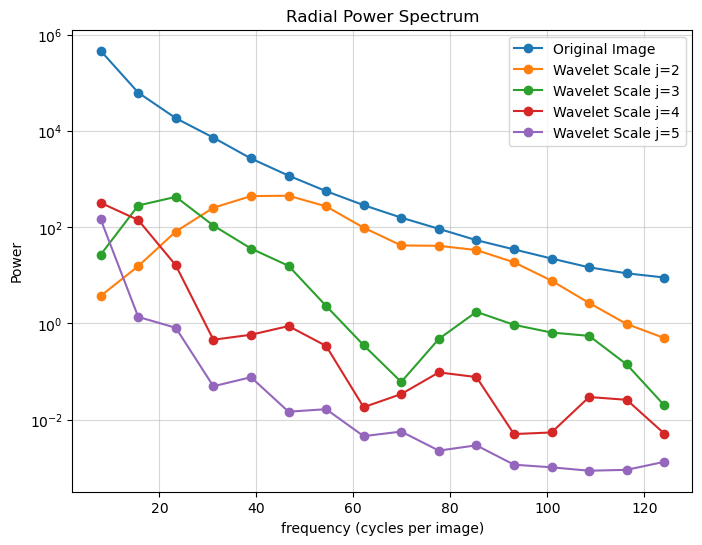

In [47]:
plt.figure(figsize=(8, 6))

freqs = bin_centers.cpu().numpy()
ps_values = torch.tensor(l_data_1d_ps).cpu().numpy()
plt.plot(freqs, ps_values, "-", marker="o", label="Original Image")
# plt.plot(freqs, torch.tensor(S_j1).cpu().numpy(), "-", marker="o", label="Wavelet Scale j=1")
plt.plot(freqs, torch.tensor(S_j2).cpu().numpy(), "-", marker="o", label="Wavelet Scale j=2")
plt.plot(freqs, torch.tensor(S_j3).cpu().numpy(), "-", marker="o", label="Wavelet Scale j=3")
plt.plot(freqs, torch.tensor(S_j4).cpu().numpy(), "-", marker="o", label="Wavelet Scale j=4")
plt.plot(freqs, torch.tensor(S_j5).cpu().numpy(), "-", marker="o", label="Wavelet Scale j=5")

plt.yscale("log")
plt.xlabel("frequency (cycles per image)")
plt.ylabel("Power")
plt.title("Radial Power Spectrum")
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend()